# Número reproductivo efectivo $R_t$ de varicela: cálculo nacional semanal

Este cuaderno estima $R_t$ para Colombia entre 2008 y 2025 a partir de notificaciones semanales; el resultado se publica en `docs/data_processed/numero_reproductivo/rt_national_weekly.csv`. $R_t$ es el número reproductivo instantáneo: las infecciones secundarias esperadas por persona infectada si las condiciones de transmisión del día $t$ persistieran durante su período infeccioso. La implementación en Python sigue `parametric_si` de EpiEstim, que requiere una distribución supuesta del **intervalo serial**: el tiempo entre el inicio de síntomas de un transmisor y el de su caso secundario.

**Modelo de renovación.** En la formulación de [Fraser (2007)](https://doi.org/10.1371/journal.pone.0000758) usada por [Cori et al. (2013)](https://doi.org/10.1093/aje/kwt133), $C_d$ cuenta las infecciones nuevas del día $d$ y $w_s$ es el peso de transmisión de quienes se infectaron $s$ días antes; los pesos son no negativos y suman 1. En el modelo ideal provienen del intervalo de generación, el tiempo entre dos infecciones relacionadas. Por eso, $\Lambda_d=\sum_{s\ge1}w_sC_{d-s}$ suma la incidencia anterior ponderada por su rezago: es una cantidad calculada, no un conteo de personas infecciosas observadas; por ejemplo, 10 casos con peso 0,2 aportan 2 unidades a $\Lambda_d$. Si $R_d$ denota el número reproductivo instantáneo del día $d$, el modelo establece $\mathbb{E}[C_d\mid C_{<d},R_d]=R_d\Lambda_d$. Esa igualdad fija solo la media condicional. [Cori et al. (2013)](https://doi.org/10.1093/aje/kwt133) añaden el supuesto $C_d\mid C_{<d},R_d\sim\operatorname{Poisson}(R_d\Lambda_d)$ para describir la variación de los conteos.

**Datos utilizados.** No observamos $C_d$: agrupamos las notificaciones por semana de `FEC_NOT` (fecha de notificación) y reconstruimos una serie diaria $I_d^*$ dentro de cada semana registrada. Aplicamos pesos derivados del intervalo serial a esa serie, con $\Lambda_d^*=\sum_{s\ge1}w_sI_{d-s}^*$, y usamos $I_d^*\sim\operatorname{Poisson}(R_d\Lambda_d^*)$. Una demora entre síntomas y notificación puede mover casos a otra semana y suavizar cambios; [Gostic et al. (2020)](https://doi.org/10.1371/journal.pcbi.1008409) explican este problema para la estimación temporal de $R_t$. La sección 3 examina los retrasos en los datos colombianos. Por ello, interpretar esta serie como transmisión requiere supuestos sobre el registro que no quedan verificados por el modelo.

**Intervalo serial y ventana.** A partir de 184 intervalos de varicela recogidos por [R. E. H. Simpson (1952)](https://doi.org/10.1016/S0140-6736(52)91357-3) en Inglaterra, [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209) modelaron el tiempo entre el inicio de síntomas de un caso transmisor y el de su caso secundario: **14,1 días en promedio**, con **2,4 días de desviación estándar** entre intervalos. Esta desviación describe la dispersión de los tiempos entre pares de casos, no la incertidumbre de la media. [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209) obtuvieron además una media agrupada de 14,0 días entre tres estudios. Elegimos ventanas móviles de **14 días** porque se aproximan a esa duración y abarcan dos semanas completas de notificaciones. Dentro de cada ventana suponemos un único $R_t$, identificado por su día final $t$; es una aproximación que suaviza las estimaciones. La [guía de EpiEstim](https://mrc-ide.github.io/EpiEstim/articles/full_EpiEstim_vignette.html) orienta la elección de ventanas según el intervalo serial y, con [datos agregados](https://mrc-ide.github.io/EpiEstim/articles/EpiEstim_aggregated_data.html), según el período de agregación. [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209) no establecieron una ventana óptima para $R_t$.

**Inferencia e interpretación.** A cada $R_t$ asignamos una **previa** —distribución antes de incorporar los conteos de su ventana— $\operatorname{Gamma}(a=1,b=0{,}2)$, con forma $a$ y tasa $b$. Su media y desviación estándar son 5. [Thompson et al. (2019)](https://doi.org/10.1016/j.epidem.2019.100356) explican que una media previa alta hace más exigente concluir $R_t<1$, mientras que una dispersión amplia reduce el peso de la previa cuando hay datos. Es la [elección predeterminada de EpiEstim](https://mrc-ide.github.io/EpiEstim/reference/estimate_R.html), no una estimación colombiana: su intervalo previo central del 95 % es $[0{,}13;18{,}44]$. Como contexto, [Barrero Guevara et al. (2023)](https://doi.org/10.1093/infdis/jiad244) documentaron diferencias estacionales entre municipios colombianos y modelaron efectos de humedad y calendario escolar. Esa heterogeneidad motiva no imponer una previa estrecha para todas las ventanas. El [panel C de la Figura 4 del artículo](https://pmc.ncbi.nlm.nih.gov/articles/PMC10503957/figure/jiad244-F4/) muestra cómo cambia durante el año el componente estacional de la tasa de contagio en el modelo de esos autores para Cúcuta y Bogotá. Esa magnitud es distinta del número reproductivo instantáneo $R_t$ calculado aquí; por ello, las cifras de la figura no permiten deducir la forma $a=1$ ni la tasa $b=0{,}2$ de nuestra previa. Al combinarla con el modelo Poisson obtenemos una **posterior**, la distribución de $R_t$ después de incorporar los datos, y un intervalo creíble del 95 % condicionado a los supuestos del modelo. Las secciones siguientes detallan esos cálculos y sus límites. $R_t>1$ sugiere crecimiento y $R_t<1$ descenso dentro del modelo; $R_0$, el número reproductivo básico en una población completamente susceptible, es otra cantidad. Los cambios de notificación, las importaciones, el herpes zóster y la mezcla de edades y territorios limitan la interpretación causal de $R_t$.


## 1. Preparación y procedencia

Usamos `docs/data_processed/evolucion_semanal/weekly_series_2007_2025.csv`, generado desde `casos_total` del [conjunto Parquet de Sivigila](../data/sivigila_integrado_notification_semanal_municipal.parquet/), el sistema colombiano de vigilancia en salud pública. Seleccionamos `age_group == "all"`, que reúne todas las edades; 2007 queda fuera por la discrepancia de cobertura documentada en el README. La tasa por 100.000 personas sirve para contexto, **no** entra en la ecuación de renovación. El modelo necesita conteos.

Ejecuta desde la raíz del repositorio o desde `notebooks/`. Requiere `numpy`, `pandas`, `scipy` y `matplotlib` de `requirements.txt`. Las fuentes metodológicas están al final.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gamma

from sys import path as python_path
# Permite ejecutar el cuaderno desde la raíz del repositorio o desde notebooks/.
ROOT = Path.cwd()
if not (ROOT / "scripts/generate_rt_national.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "scripts/generate_rt_national.py").exists(), "Abre el notebook desde la raíz o notebooks/"
python_path.insert(0, str(ROOT / "scripts"))
from generate_rt_national import build_series, estimate_rt, serial_weights

# Una fila de «serie» equivale a una semana epidemiológica nacional.
serie = build_series(ROOT / "docs/data_processed/evolucion_semanal/weekly_series_2007_2025.csv")
print(f"{len(serie)} semanas, {serie.year.min()}–{serie.year.max()}")
print(serie.loc[serie.missing_week, ["year", "week", "notifications", "missing_week"]])
# Estas condiciones comprueban que el calendario está completo y localizan el único vacío.
assert len(serie) == 940
assert serie.loc[serie.missing_week, ["year", "week"]].values.tolist() == [[2008, 52]]

940 semanas, 2008–2025
    year  week  notifications  missing_week
51  2008    52            NaN          True


## 2. La semana sin registro y la regla de auditoría

La semana epidemiológica 52 de 2008 (2008-S52) permanece **sin conteo**; una semana sin registro no equivale a cero casos. El procedimiento reconstruye días **dentro de cada semana observada**, pero no inventa el total de la semana faltante. La serie se divide en dos tramos y no se arrastra infecciosidad de uno al otro. La marca `missing_week` identifica la semana sin dato (2008-S52). La marca `missing_affected` identifica esa semana y las dos siguientes (2008-S53 y 2009-S01), afectadas por la falta de historia al reiniciar la reconstrucción. La ventana de 14 días deja además 2009-S02 sin estimación, aunque no lleva esa marca. También se omiten estimaciones al comienzo de 2008 por falta de historia anterior dentro del período analítico.
La primera estimación posterior al vacío aparece en **2009-S03**; se calcula después del reinicio sin recuperar la historia omitida y debe leerse con cautela.


In [2]:
# Mostramos semanas vecinas para distinguir una semana sin dato de una semana con cero.
vecinas = serie.loc[(serie.year == 2008) & serie.week.between(50, 53),
                    ["year", "week", "notifications", "missing_week"]]
display(vecinas)
assert pd.isna(vecinas.loc[vecinas.week == 52, "notifications"].iloc[0])
assert vecinas.loc[vecinas.week == 52, "missing_week"].iloc[0]
print("2008-S52 queda sin notificaciones observadas; no se reemplaza por cero ni por interpolación.")

,year,week,notifications,missing_week
49,2008,50,165.0,False
50,2008,51,1.0,False
51,2008,52,NaN,True
52,2008,53,1.0,False


2008-S52 queda sin notificaciones observadas; no se reemplaza por cero ni por interpolación.


## 3. Intervalo serial continuo y pesos diarios

Para entender qué representan los pesos de la ecuación de renovación, hay que distinguir tres momentos: **infección**, **inicio de síntomas** y **semana en que el caso queda registrado**. El **intervalo de generación** $G$ mide el tiempo entre la infección de una persona transmisora y la infección de su caso secundario. El **intervalo serial** $S$ mide el tiempo entre sus respectivos inicios de síntomas. Si $T_i$ es la fecha de infección y $L_i$ el periodo de incubación de cada persona, su inicio de síntomas es $O_i=T_i+L_i$. Para un par transmisor $i$–secundario $j$ se cumple exactamente:

$$G_{ij}=T_j-T_i, \qquad S_{ij}=O_j-O_i=G_{ij}+L_j-L_i.$$

La ecuación muestra por qué no se pueden identificar los dos intervalos sin más información. Si los periodos de incubación de transmisores y secundarios tienen la misma media, las medias de $S$ y $G$ coinciden; **eso no implica que sus distribuciones coincidan**. La variabilidad de la incubación y su relación con el momento de transmisión pueden cambiar la dispersión y la forma del intervalo serial. Para tratar su distribución como si fuera la del intervalo de generación hacen falta supuestos adicionales sobre esa relación. La incubación media, por sí sola, no permite deducir ni la media ni la desviación del intervalo serial. Véase [Lehtinen et al. (2021)](https://pmc.ncbi.nlm.nih.gov/articles/PMC7879757/).

La **incidencia de infecciones** cuenta cuántas personas se infectan cada semana; en una ecuación de renovación construida con esa serie, los pesos de los rezagos corresponden al intervalo de generación. La **incidencia de inicios de síntomas** cuenta cuántas personas comienzan a presentar síntomas cada semana; una renovación construida con esa serie puede formularse con intervalos seriales definidos de forma adecuada, como en el enfoque de [Cori et al. (2013)](https://pmc.ncbi.nlm.nih.gov/articles/PMC3816335/). La serie agregada de este cuaderno no contiene ninguna de esas dos incidencias: $I_t$ cuenta **casos agrupados por la semana epidemiológica de `FEC_NOT`**. Los retrasos y cambios en el registro pueden desplazar o difuminar el patrón temporal de las infecciones.

Usar notificaciones semanales es pertinente para describir la vigilancia: el [protocolo del INS](https://www.ins.gov.co/buscador-eventos/Lineamientos/Pro_Varicela.pdf) construye canales endémicos con ellas y [Barrero Guevara et al. (2023)](https://doi.org/10.1093/infdis/jiad244) analizaron series semanales de Sivigila. Para examinar cuánto separan el inicio de síntomas del registro, el [análisis reproducible de la demora](03_demora_notificacion_sivigila.ipynb) calcula `FEC_NOT − INI_SIN` en los **CSV individuales** usados para generar el [Parquet por semana de notificación](../data/sivigila_integrado_notification_semanal_municipal.parquet/) y el [Parquet por semana de síntomas](../data/sivigila_integrado_symptom_semanal_municipal.parquet/). Los Parquet son agregados y no conservan ambas fechas individuales. Entre los registros incluidos de 2008–2025 con las dos fechas interpretables ($n=1.169.382$), la mediana fue **2 días**, el rango intercuartílico **1–4 días** y **788.368 (67,4 %)** se notificaron entre el inicio de síntomas y tres días después. La proporción con más de siete días de demora aumentó de **4,6 % en 2009–2011** a **17,7 % en 2019–2025**. Así, aunque muchos casos se registran pronto, la demora no fue estable. El cálculo de $R_t$ supone que los pesos seriales aproximan razonablemente los rezagos entre notificaciones y que los retrasos de registro no distorsionan mucho ese patrón; estas cifras **no verifican ese supuesto**.

En la variante `notification`, es decir, la serie agrupada por fecha de notificación utilizada aquí, la semana epidemiológica **se asigna a partir de `FEC_NOT`**. Sea $O_i$ el inicio de síntomas, $N_i$ la fecha de notificación y $D_i=N_i-O_i$ el retraso de un caso. Para un par transmisor–caso secundario identificado $(i,j)$, el intervalo entre notificaciones sería $N_j-N_i=(O_j-O_i)+(D_j-D_i)=S_{ij}+D_j-D_i$. Si el retraso fuese **exactamente igual para ambos casos**, se cancelaría y el intervalo entre notificaciones coincidiría con el serial. Un retraso solo «parecido» o estable en promedio no elimina la variación de $D_j-D_i$, así que tampoco determina la desviación estándar serial.

Los conjuntos Parquet [por semana de notificación](../data/sivigila_integrado_notification_semanal_municipal.parquet/) y [por semana de inicio de síntomas](../data/sivigila_integrado_symptom_semanal_municipal.parquet/) contienen conteos agregados por entidad y semana, pero **no identifican pares de transmisión**. El retraso `FEC_NOT − INI_SIN` se puede describir dentro de cada caso; no da el tiempo entre síntomas de quien infecta y de quien resulta infectado. Por ello **no se pueden estimar con estos datos la media ni la desviación estándar del intervalo serial**, aun suponiendo retrasos de notificación estables. Para estimarlas harían falta pares epidemiológicamente vinculados con fechas de inicio de síntomas, sujetos además a posibles sesgos de selección y truncamiento ([Charniga et al., 2024](https://pmc.ncbi.nlm.nih.gov/articles/PMC11516000/)). El $R_t$ calculado sigue siendo una estimación **condicionada a estos supuestos**, no una medición directa del número de infecciones secundarias. Los intervalos creíbles de $R_t$ obtenidos con la verosimilitud Poisson y la previa Gamma no incluyen la incertidumbre sobre los pesos, el retraso de registro o los cambios de vigilancia; [Gostic et al. (2020)](https://doi.org/10.1371/journal.pcbi.1008409) explican cómo estos factores pueden afectar la estimación.

Para el escenario principal tomamos la estimación de [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209), tabla 3, basada en 184 pares de casos de varicela descritos por [Simpson (1952)](https://doi.org/10.1016/S0140-6736(52)91357-3) en Inglaterra entre 1947 y 1951. Si $S$ es el número de días entre el inicio de síntomas del caso transmisor y el de su caso secundario, [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209) modelan su distribución como $S\sim N(14{,}1;2{,}4^2)$: el primer parámetro es la **media estimada**, 14,1 días, y el segundo es la **varianza**, $2{,}4^2$ días cuadrados. La desviación estándar de 2,4 días expresa cuánto varían los intervalos entre pares alrededor de esa media; no es el error estándar de la media ni la duración de la infecciosidad. [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209) estiman una media agrupada de 14,0 días a partir de tres estudios. Su tabla conserva variación entre muestras y el artículo advierte la escasez y heterogeneidad de la evidencia; por eso comparamos los tres pares de parámetros publicados en la sección 7. Son antecedentes bibliográficos, no estimaciones colombianas ni valores calculados de Sivigila.

Para seguir `parametric_si`, aproximamos la distribución serial de [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209) con la Gamma desplazada que usa EpiEstim: $S=1+X$ días, $X\sim\operatorname{Gamma}(\alpha,\theta)$, con **forma** $\alpha=((\mu-1)/\sigma)^2$ y **escala** $\theta=\sigma^2/(\mu-1)$; $\mu=14{,}1$ días y $\sigma=2{,}4$ días son la media y la desviación estándar del intervalo serial. El artículo modela principalmente con una distribución normal y reporta que el ajuste Gamma da resultados similares; la implementación paramétrica de EpiEstim usa la Gamma desplazada. La [función `discr_si()` de EpiEstim](https://mrc-ide.github.io/EpiEstim/reference/discr_si.html) convierte esa distribución continua en un peso $w_s$ para cada rezago de $s$ días: el peso indica qué proporción de la transmisión se atribuye en el modelo a casos ocurridos $s$ días antes. La rutina Python reproduce esa fórmula de discretización, y la reconstrucción diaria sigue la [guía de incidencia agregada](https://mrc-ide.github.io/EpiEstim/articles/EpiEstim_aggregated_data.html). Una [comparación reproducible con EpiEstim 2.4 en R](04_comparacion_epiestim_r_python.ipynb) coteja pesos, reconstrucción diaria y posterior en tres tramos nacionales de 20 semanas: las diferencias numéricas máximas son menores de $10^{-8}$. Esta concordancia verifica la implementación en esos tramos, no los supuestos epidemiológicos.

El [Parquet `symptom`](../data/sivigila_integrado_symptom_semanal_municipal.parquet/), que agrupa los casos por inicio de síntomas, conserva 1.195.823 casos frente a 1.251.524 en `notification` (55.701 menos; 4,45 %). Es una comparación necesaria del calendario de incidencia, pero tampoco identifica pares de transmisión para estimar $\mu$ o $\sigma$. Los intervalos creíbles de $R_t$ siguen sin incluir la incertidumbre de esos parámetros, del retraso de registro ni de los cambios de vigilancia.

,rezago_dias,peso
0,1,1.266167e-24
1,2,2.839920e-16
2,3,9.161630e-12
3,4,7.950887e-09
4,5,9.489152e-07
5,6,3.190750e-05
6,7,4.417932e-04
7,8,3.164304e-03
8,9,1.361894e-02
9,10,3.910203e-02


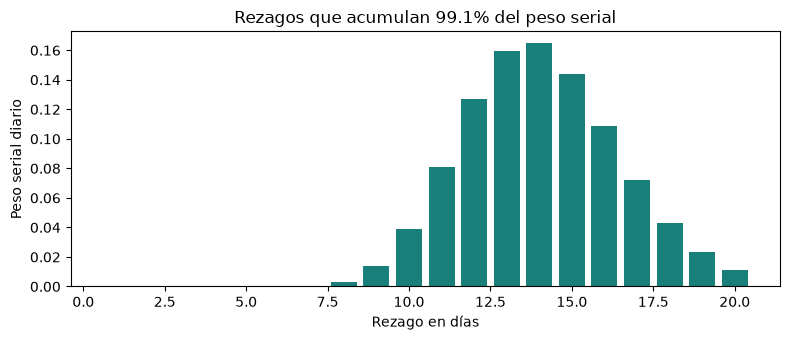

In [3]:
from epiestim_parametric_weekly import discr_si, estimate_with_gaps

# I tiene un valor por SEMANA; sus valores faltantes permanecen como NaN.
I = serie.notifications.to_numpy(dtype=float)
pesos_diarios = discr_si(np.arange(90), mean_days=14.1, sd_days=2.4)
assert np.isclose(pesos_diarios.sum(), 1, atol=1e-9)
# Lambda es infectividad agregada por semana; posterior tiene media y dos cuantiles.
# «bloques» separa los tramos observados a cada lado de 2008-S52.
Lambda, posterior, bloques = estimate_with_gaps(I, 14.1, 2.4, window_weeks=2)

# Mostrar el tramo más corto que contiene el 99 % de la masa de probabilidad.
# La suma acumulada indica hasta qué rezago diario se concentra el 99 % del peso.
rezago_99 = int(np.searchsorted(np.cumsum(pesos_diarios), 0.99))
rezagos = np.arange(1, rezago_99 + 1)
masa_mostrada = pesos_diarios[:rezago_99 + 1].sum()
assert masa_mostrada >= 0.99

display(pd.DataFrame({"rezago_dias": rezagos, "peso": pesos_diarios[rezagos]}))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(rezagos, pesos_diarios[rezagos], color="#197f7a")
ax.set(xlabel="Rezago en días", ylabel="Peso serial diario",
       title=f"Rezagos que acumulan {masa_mostrada:.1%} del peso serial")
plt.tight_layout()
plt.show()

### Cómo leer los días de rezago del gráfico

Sivigila aporta registros individuales con `FEC_NOT`; en este trabajo, el [repositorio `data-processing`](https://github.com/thesis-varicella-colombia/data-processing/blob/main/data/processed/sivigila/README.md) los agrupó por semana de notificación. Es posible construir conteos diarios directamente con esas fechas, pero este cuaderno parte de los totales semanales publicados para reproducir la ruta de incidencia agregada. Para aplicar pesos diarios, el algoritmo **reconstruye** una serie diaria estimada: primero reparte por igual el total semanal entre sus siete días y luego ajusta ese reparto según el crecimiento estimado, conservando siempre el total original de la semana. Por ejemplo, una semana con 700 notificaciones comienza como 100 por día; el ajuste puede dejar unos días con más y otros con menos, pero los siete valores siguen sumando 700. Esos valores calculados se escriben como $I_d^*$; no son conteos diarios observados ni fechas reales de cada caso.

La reconstrucción solo distribuye los totales de semanas que sí tienen datos. No inventa el conteo de la semana 52 de 2008, que permanece faltante.

El eje horizontal cuenta hacia atrás desde cualquier día reconstruido $t$ de la serie: rezago 1 es el día reconstruido inmediatamente anterior ($t-1$); rezago 5 es cinco días antes; rezago 14 es dos semanas antes.

En la interpretación epidemiológica habitual, un intervalo serial de 14 días significa 14 días entre los inicios de síntomas del transmisor y el caso secundario. La barra $w_{14}$, de aproximadamente 0,165 con los parámetros principales de Simpson (media 14,1 y desviación estándar 2,4 días), expresa el peso que se asigna a ese rezago. Si la reconstrucción tuviera 100 casos en $t-14$, estos aportarían $100\times0{,}165=16{,}5$ unidades ponderadas a $\Lambda_t^*$. Esa cantidad todavía no es un número esperado de casos. En la ecuación de renovación, el número esperado para el día $t$ es $E[I_t^*\mid R_t,\Lambda_t^*]=R_t\Lambda_t^*$. Por ejemplo, si hipotéticamente $R_t=1{,}2$ y ese fuera el único aporte a $\Lambda_t^*$, la contribución esperada sería $1{,}2\times16{,}5=19{,}8$ casos reconstruidos en $t$; en el cálculo real se suman los aportes de todos los rezagos y $R_t$ también tiene incertidumbre. Esto no identifica quién contagió a quién ni estima directamente infecciones reales a partir de las notificaciones.

Aquí el peso serial se aplica a notificaciones ubicadas en semanas de `FEC_NOT`, no a pares de inicios de síntomas enlazados. Por eso, interpretar $t-14$ como un intervalo biológico real requiere que los retrasos de registro no deformen sustancialmente la escala temporal. La figura muestra los rezagos que acumulan el 99 % del peso de la distribución supuesta.


 ## 4. Reconstrucción diaria e infecciosidad

Para una semana observada con $N_w$ notificaciones, EpiEstim inicia con $N_w/7$ en cada día reconstruido. Después alterna entre estimar $R$ para cada semana y redistribuir el total diario según una curva exponencial ligada al crecimiento estimado, **conservando la suma semanal**. Tras diez iteraciones, la serie diaria estimada $I_d^*$ permite calcular, para cada día $d$,

$$\Lambda_d^*=\sum_{s\ge1}w_s I_{d-s}^*.$$

$\Lambda_d^*$ es la suma ponderada de los conteos diarios reconstruidos anteriores a $d$. Resume cuánta incidencia previa aporta al modelo para explicar los casos del día $d$; **no es un conteo observado de personas infecciosas ni de casos nuevos**. En la ecuación de renovación, el número esperado de casos diarios reconstruidos es $R_d\Lambda_d^*$.

La reconstrucción dentro de semanas es un supuesto del modelo y no recupera fechas individuales reales. En el CSV, `lambda_t` es la **suma de las siete cantidades diarias** $\Lambda_d^*$ de esa semana; por tanto, es un acumulado semanal de casos previos ponderados, no el valor de un solo día. Como $R_t$ se estima en ventanas de dos semanas, el parámetro de tasa de su posterior suma los `lambda_t` de ambas semanas. La reconstrucción se reinicia después de 2008-S52.

In [4]:
# t es la posición GLOBAL de 2008-S08 entre las semanas de la serie completa.
t = serie.index[(serie.year == 2008) & (serie.week == 8)][0]
indices_2008, bloque_2008 = bloques[0]
assert t in indices_2008
# local es la posición de esa misma semana dentro del primer tramo sin vacíos.
local = int(np.flatnonzero(indices_2008 == t)[0])
fechas = np.arange(1, 15)
# Cada semana reconstruida ocupa 7 posiciones; S07–S08 suma 14 días.
dias = slice((local - 1) * 7, (local + 1) * 7)
ejemplo = pd.DataFrame({"dia_en_semana": fechas,
                        "incidencia_reconstruida": bloque_2008.daily_incidence[dias],
                        "infecciosidad": bloque_2008.daily_infectiousness[dias]})
display(ejemplo.round(3))
assert np.isclose(ejemplo.incidencia_reconstruida.sum(), I[t-1:t+1].sum())
assert np.isclose(ejemplo.infecciosidad.sum(), Lambda[t-1:t+1].sum())
print(f"Ventana de dos semanas terminada en 2008-S08: {I[t-1:t+1].sum():.0f} notificaciones; infecciosidad acumulada {Lambda[t-1:t+1].sum():.2f}")

# Inspeccionamos el hueco y las semanas de reinicio de la estimación.
auditoria = serie.loc[((serie.year == 2008) & (serie.week >= 50)) |
                     ((serie.year == 2009) & (serie.week <= 4)),
                     ["year", "week", "notifications", "missing_week"]].copy()
auditoria["lambda_t"] = Lambda[auditoria.index]
auditoria["rt"] = posterior[auditoria.index, 0]
display(auditoria)
assert np.isnan(posterior[serie.index[(serie.year == 2008) & (serie.week == 52)][0]:
                            serie.index[(serie.year == 2009) & (serie.week == 1)][0] + 1]).all()
assert not np.isfinite(posterior[serie.index[(serie.year == 2009) & (serie.week == 2)][0], 0])
assert np.isfinite(posterior[serie.index[(serie.year == 2009) & (serie.week == 3)][0], 0])

,dia_en_semana,incidencia_reconstruida,infecciosidad
0,1,108.897,114.192
1,2,108.789,111.675
2,3,108.680,109.866
3,4,108.571,108.952
4,5,108.463,108.905
5,6,108.354,109.537
6,7,108.246,110.554
7,8,113.089,111.637
8,9,113.202,112.536
9,10,113.315,113.100


Ventana de dos semanas terminada en 2008-S08: 1554 notificaciones; infecciosidad acumulada 1561.32


,year,week,notifications,missing_week,lambda_t,rt
49,2008,50,165.0,False,1493.927015,0.443656
50,2008,51,1.0,False,1184.804803,0.062338
51,2008,52,NaN,True,NaN,NaN
52,2008,53,1.0,False,0.000005,NaN
53,2009,1,1133.0,False,0.134492,NaN
54,2009,2,1235.0,False,146.907466,NaN
55,2009,3,1327.0,False,936.243909,2.365807
56,2009,4,1348.0,False,1219.568621,1.241180


## 5. Posterior Gamma en una ventana de dos semanas

**Ventana de estimación.** Calculamos un $R_t$ para cada ventana móvil de 14 días y suponemos que permanece constante dentro de ella. Así, cada estimación resume la transmisión compatible con esas dos semanas y suaviza cambios más rápidos; ventanas más largas suavizarían aún más. Elegimos 14 días porque se aproximan a la media de 14,1 días estimada por [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209) con los datos de [Simpson (1952)](https://doi.org/10.1016/S0140-6736(52)91357-3) y abarcan dos semanas completas de notificaciones. Vink et al. también obtuvieron una media agrupada de 14,0 días a partir de tres estudios de varicela. La [guía de EpiEstim](https://mrc-ide.github.io/EpiEstim/articles/full_EpiEstim_vignette.html) sugiere comenzar con una ventana al menos tan larga como la media serial; para [datos agregados](https://mrc-ide.github.io/EpiEstim/articles/EpiEstim_aggregated_data.html), recomienda no usar una ventana menor que el período de agregación. Los 14 días son una elección de análisis, no una duración óptima demostrada ni una recomendación de Vink et al.

**Modelo diario.** Dentro de cada ventana, suponemos $I_d^*\sim\operatorname{Poisson}(R_t\Lambda_d^*)$, donde $I_d^*$ es la incidencia diaria reconstruida y $\Lambda_d^*$ suma los casos reconstruidos de días anteriores ponderados por el intervalo serial. Es la verosimilitud que relaciona los datos con $R_t$.

**Elección de la previa.** Antes de incorporar los conteos de cada ventana, asignamos a $R_t$ una distribución Gamma con media 5 y desviación estándar 5. La media representa el valor esperado previo y la desviación expresa una incertidumbre amplia; no son estimaciones obtenidas de casos de varicela. En el [suplemento de Cori et al. (2013), apéndice 10](https://bosailiteracy.org/wp-content/uploads/2020/05/Supplementary-Data.pdf) se compararon previas con medias 1, 5, 10 y 50 y desviaciones iguales a sus medias. [Thompson et al. (2019)](https://doi.org/10.1016/j.epidem.2019.100356) usaron 5 y 5 siguiendo a Cori, y [EpiEstim](https://mrc-ide.github.io/EpiEstim/reference/estimate_R.html) los adoptó como valores predeterminados. Ninguno de esos trabajos calibró esta previa para Colombia.

Para una Gamma de forma $a$ y **tasa** $b$, $\mathbb{E}[R_t]=a/b$ y $\operatorname{DE}(R_t)=\sqrt{a}/b$. Con media y desviación estándar iguales a 5 se obtiene $a=(5/5)^2=1$ y $b=5/5^2=0{,}2$; por tanto, $R_t\sim\operatorname{Gamma}(1;0{,}2)$. Su intervalo central previo del 95 % es aproximadamente $[0{,}13;18{,}44]$: admite valores cercanos a 1 y también valores mayores. [Pawaskar et al. (2022)](https://doi.org/10.1016/j.vaccine.2022.07.012) documentaron una reducción de la incidencia colombiana tras introducir la vacunación universal en 2015, hasta 2019, pero no estimaron $R_t$. En una población francesa, [Silhol y Boëlle (2011)](https://doi.org/10.1371/journal.pcbi.1002105) obtuvieron $R_0$ cercano a 4 o 14 según el modelo. Esos valores muestran la amplitud de posibles escalas de transmisión, pero $R_0$ no equivale al $R_t$ de Colombia y no valida los parámetros previos elegidos.

**Actualización con los datos.** Al combinar esa previa con la verosimilitud de los 14 días, la posterior sigue siendo Gamma:

$$R_t\mid I^*\sim\operatorname{Gamma}\left(a+\sum_{d=t-13}^{t}I_d^*,\;b+\sum_{d=t-13}^{t}\Lambda_d^*\right).$$

La primera suma es el conteo de casos de las dos semanas; la segunda es la infectividad acumulada calculada con la reconstrucción y los pesos seriales. En esta fórmula, $a=1$ aporta un pseudocaso y $b=0{,}2$ aporta 0,2 unidades de infectividad. Entre las ventanas con estimación publicada en `docs/data_processed/numero_reproductivo/rt_national_weekly.csv`, los conteos bisemanales son al menos 166 y la infectividad acumulada es al menos 224,06. En la comparación de sensibilidad de abajo, una previa muy distinta cambia la media posterior como máximo en 0,0259. La influencia de esta previa es pequeña en estas ventanas nacionales, aunque puede ser mayor cuando hay pocos casos.

Publicamos la media y los cuantiles 2,5 % y 97,5 % de esa posterior. El intervalo creíble es **condicional** al modelo Poisson, al intervalo serial y a la reconstrucción diaria; no incluye posibles errores de vigilancia.

### Comprobación manual de la semana 2008-S08

La celda siguiente verifica **una** estimación ya calculada: la de 2008-S08. En la sección anterior, `t` quedó definido como la posición de esa semana en la serie nacional de **semanas**, `local` como su posición dentro del primer tramo continuo (`bloque_2008`) y `posterior[t]` contiene, en ese orden, la media y los límites creíbles inferior y superior publicados para esa semana. `daily_incidence` y `daily_infectiousness` son vectores **diarios reconstruidos** dentro de ese tramo.

La ventana termina el sábado de S08 y comprende **S07 y S08**, siete días por semana. Python incluye el extremo inicial de `slice(inicio, fin)` y excluye `fin`; por eso el inicio `(local-1)×7` y el fin `(local+1)×7` seleccionan exactamente **14 valores diarios**. Al sumarlos obtenemos, por separado, los casos reconstruidos y la infectividad calculada de esa ventana. Luego añadimos los parámetros previos, 1 a la **forma** y 0,2 a la **tasa**. `gamma.ppf` espera una **escala**, que es el inverso de la tasa: `scale=1/b_post`. La última línea comprueba que este cálculo directo coincide con `posterior[t]`; no es un segundo método de estimación.


In [5]:
inicio = (local - 1) * 7             # primer día de S07 dentro del tramo
fin_exclusivo = (local + 1) * 7     # día siguiente al último de S08
# El extremo final del slice queda excluido: se seleccionan exactamente 14 días.
dias_ventana = slice(inicio, fin_exclusivo)
casos_14_dias = bloque_2008.daily_incidence[dias_ventana].sum()
infectividad_14_dias = bloque_2008.daily_infectiousness[dias_ventana].sum()
assert fin_exclusivo - inicio == 14

# Actualización conjugada: forma = pseudocaso previo + casos de la ventana.
a_post = 1 + casos_14_dias
# Tasa = exposición previa + infectividad acumulada de esos mismos 14 días.
b_post = 0.2 + infectividad_14_dias
# SciPy recibe escala, que es el inverso de nuestra tasa Gamma.
resumen_manual = np.array([
    a_post / b_post,                              # media posterior
    gamma.ppf(.025, a=a_post, scale=1 / b_post),  # cuantil inferior
    gamma.ppf(.975, a=a_post, scale=1 / b_post),  # cuantil superior
])
print(f"Ventana S07–S08: {casos_14_dias:.0f} casos reconstruidos; "
      f"{infectividad_14_dias:.2f} unidades de infectividad")
print(f"Posterior: forma={a_post:.2f}; tasa={b_post:.2f}")
print("Media y límites creíbles del 95 %:", np.round(resumen_manual, 4))
assert np.allclose(resumen_manual, posterior[t])

Ventana S07–S08: 1554 casos reconstruidos; 1561.32 unidades de infectividad
Posterior: forma=1555.00; tasa=1561.52
Media y límites creíbles del 95 %: [0.9958 0.9469 1.0459]


### Dispersión posterior en todas las semanas estimables

Para una posterior $\operatorname{Gamma}(a_{\mathrm{post}},b_{\mathrm{post}})$ de **tasa** $b_{\mathrm{post}}$, su **coeficiente de variación** (CV) es la desviación estándar dividida por la media:

$$\mathrm{CV}=\frac{\sqrt{a_{\mathrm{post}}}/b_{\mathrm{post}}}{a_{\mathrm{post}}/b_{\mathrm{post}}}=\frac{1}{\sqrt{a_{\mathrm{post}}}}.$$

En una ventana de 14 días, $a_{\mathrm{post}}=1+\text{casos de S07 y S08}$. Como la reconstrucción diaria conserva exactamente el total de cada semana, podemos calcular esa forma sumando **dos entradas consecutivas de `I`**, que es un vector **semanal**. `rolling(2)` significa dos semanas, equivalentes a los 14 días de la ventana; `rolling(14)` habría sumado **14 semanas** y dado un CV incorrecto. Solo contamos las semanas con posterior finita. El umbral CV ≤ 10 % describe dispersión **dentro de la posterior Poisson–Gamma**, no incorpora errores de vigilancia ni demuestra precisión del $R_t$ biológico.

In [6]:
# Solo evaluamos CV donde hay una posterior semanal publicada.
semanas_estimadas = np.isfinite(posterior[:, 0])
# I es SEMANAL: dos entradas consecutivas representan la ventana de 14 días.
casos_en_dos_semanas = pd.Series(I).rolling(window=2, min_periods=2).sum().to_numpy()
formas_estimadas = 1 + casos_en_dos_semanas[semanas_estimadas]
assert np.isfinite(formas_estimadas).all()
# Para Gamma, desviación estándar / media = 1 / raíz(forma posterior).
cv_posterior = 1 / np.sqrt(formas_estimadas)
print(f"CV posterior ≤ 10 % en {(cv_posterior <= .1).sum()} de "
      f"{len(cv_posterior)} semanas estimables")

CV posterior ≤ 10 % en 933 de 933 semanas estimables


### Influencia de la previa

Comparamos la previa principal de EpiEstim, Gamma de forma 1 y tasa 0,2 (media 5, desviación estándar 5, varianza 25), con una previa alternativa Gamma de forma 1 y tasa 5 (media 0,2, desviación estándar 0,2, varianza 0,04). Mantenemos fijos los conteos, la reconstrucción y los pesos. La alternativa es deliberadamente distinta para mostrar cuánto puede influir la previa, sobre todo con pocos casos; no implica que alguna de las dos esté validada específicamente para varicela.

In [6]:
# Repetimos el cálculo con otra previa, manteniendo datos y pesos seriales.
_, posterior_anterior, _ = estimate_with_gaps(
    I, 14.1, 2.4, window_weeks=2, prior_mean=.2, prior_sd=.2
)
# Comparamos solo la media posterior; los NaN del vacío se ignoran al resumir.
diferencia = np.abs(posterior[:, 0] - posterior_anterior[:, 0])
print(f"Máxima diferencia absoluta en la media posterior: {np.nanmax(diferencia):.6f}")
print(f"Mediana de diferencia absoluta: {np.nanmedian(diferencia):.6f}")

Máxima diferencia absoluta en la media posterior: 0.025884
Mediana de diferencia absoluta: 0.001772


## 6. Serie completa y marcas de contexto

La banda muestra únicamente la incertidumbre posterior condicional. La línea y la banda se interrumpen entre 2008-S52 y 2009-S01; la franja naranja señala ese vacío de estimación. El umbral horizontal es $R_t=1$. Los hitos de julio de 2015 y julio de 2019 se colocan aproximadamente en la semana 27; la pandemia se sombrea desde la semana 12 de 2020 hasta terminar 2021. Estas marcas contextualizan la serie, no identifican efectos causales.

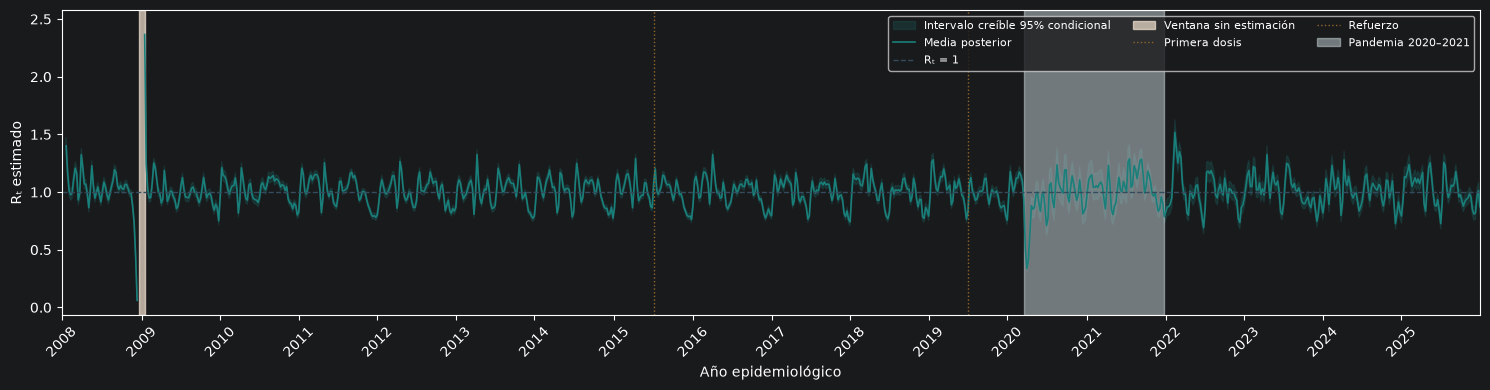

In [7]:
# Asociamos cada fila semanal con la media y los cuantiles ya calculados.
serie[["rt", "rt_lower_95", "rt_upper_95"]] = posterior
x = serie.week_position.to_numpy()
fig, ax = plt.subplots(figsize=(15, 4))
ax.fill_between(x, serie.rt_lower_95, serie.rt_upper_95, color="#197f7a", alpha=.20,
                label="Intervalo creíble 95% condicional")
ax.plot(x, serie.rt, color="#197f7a", lw=1.2, label="Media posterior")
ax.axhline(1, color="#334b5c", ls="--", lw=1, label="Rₜ = 1")
# La franja naranja indica la interrupción causada por 2008-S52.
gap_start = serie.loc[(serie.year == 2008) & (serie.week == 52), "week_position"].iloc[0]
gap_end = serie.loc[(serie.year == 2009) & (serie.week == 3), "week_position"].iloc[0]
ax.axvspan(gap_start, gap_end, color="#f5e4d3", alpha=.7, label="Ventana sin estimación")
# Las líneas verticales son marcas de contexto, no pruebas de efecto causal.
for year, label in [(2015, "Primera dosis"), (2019, "Refuerzo")]:
    point = serie.loc[(serie.year == year) & (serie.week == 27), "week_position"].iloc[0]
    ax.axvline(point, color="#94652c", ls=":", lw=1, label=label)
start = serie.loc[(serie.year == 2020) & (serie.week == 12), "week_position"].iloc[0]
end = serie.loc[(serie.year == 2021) & (serie.week == 52), "week_position"].iloc[0]
ax.axvspan(start, end, color="#cbd8dd", alpha=.5, label="Pandemia 2020–2021")
# Una etiqueta por año, situada en su primera semana epidemiológica.
ticks = serie.loc[serie.week == 1, ["week_position", "year"]]
ax.set_xticks(ticks.week_position, ticks.year, rotation=45)
ax.set(xlabel="Año epidemiológico", ylabel="Rₜ estimado", xlim=(x.min(), x.max()))
ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

## 7. Comprobación y sensibilidad

La forma supuesta del intervalo serial influye en $R_t$. Comparamos las estimaciones para varicela que presenta la tabla 3 de Vink et al. (2014): Simpson 14,1 ± 2,4 días, Vally 13,1 ± 2,2 y Lai 14,2 ± 1,3. Son estudios históricos en otros países; la comparación no estima parámetros colombianos. Un intervalo estrecho de la posterior Poisson–Gamma tampoco demuestra robustez frente a esos supuestos. Se muestran las semanas cuyos límites condicionales quedan por encima o por debajo de 1, sin interpretarlas como transmisión nacional controlada o creciente por sí solas.

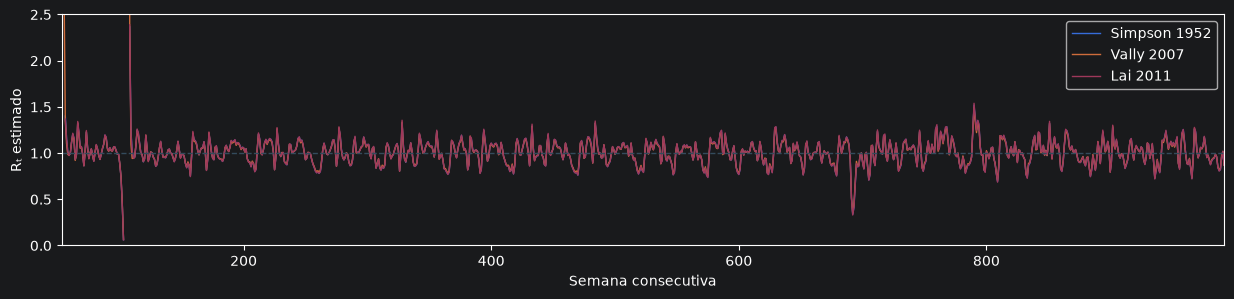

2008–2014: mediana=1.014; IC>1: 151; IC<1: 121; semanas=359
2015–2019: mediana=1.009; IC>1: 107; IC<1: 85; semanas=260
2020–2021: mediana=1.015; IC>1: 27; IC<1: 27; semanas=105
2022–2025: mediana=1.006; IC>1: 70; IC<1: 64; semanas=209


In [8]:
# Cada pareja media–DE produce pesos seriales y una serie de Rₜ distinta.
alternativas = {}
for nombre, media, sd in (("Simpson 1952", 14.1, 2.4), ("Vally 2007", 13.1, 2.2), ("Lai 2011", 14.2, 1.3)):
    _, values, _ = estimate_with_gaps(I, media, sd, window_weeks=2)
    alternativas[nombre] = values[:, 0]
fig, ax = plt.subplots(figsize=(15, 3))
for nombre, values in alternativas.items():
    ax.plot(x, values, lw=1, label=nombre)
ax.axhline(1, color="#334b5c", ls="--", lw=1)
ax.set(ylim=(0, 2.5), xlim=(x.min(), x.max()), ylabel="Rₜ estimado", xlabel="Semana consecutiva")
ax.legend(); plt.show()
# Resumimos periodos por separado; los IC son condicionales al modelo.
for inicio, fin in [(2008, 2014), (2015, 2019), (2020, 2021), (2022, 2025)]:
    tramo = serie.loc[serie.year.between(inicio, fin) & serie.rt.notna()]
    print(f"{inicio}–{fin}: mediana={tramo.rt.median():.3f}; IC>1: {(tramo.rt_lower_95>1).sum()}; IC<1: {(tramo.rt_upper_95<1).sum()}; semanas={len(tramo)}")

### Sensibilidad a la duración de la ventana

Recalculamos con ventanas de **1, 2, 3, 4 y 6 semanas** y los mismos datos, previa e intervalo serial de Simpson (media 14,1 y desviación estándar 2,4 días). La **anchura relativa** del intervalo creíble es $(R_{t,97{,}5}-R_{t,2{,}5})/\overline R_t$, donde $R_{t,q}$ es el cuantil posterior $q$ y $\overline R_t$ su media; se multiplica por 100 para expresarla en porcentaje. La tabla presenta su mediana entre las semanas comparables. También muestra las diferencias absolutas de la media posterior frente a la **ventana principal de dos semanas** y cuántas semanas cambian de lado del umbral $R_t=1$. Una ventana más larga puede dar una curva más lisa e intervalos más estrechos, pero también cambiar la fecha y magnitud aparentes de variaciones. La comparación no identifica por sí sola qué duración refleja mejor las infecciones reales.

In [9]:
# Número de semanas en cada ventana móvil de sensibilidad.
duraciones = (1, 2, 3, 4, 6)
por_ventana = {tau: estimate_with_gaps(I, 14.1, 2.4, window_weeks=tau)[1]
               for tau in duraciones}
# Comparamos solo semanas con estimación finita en TODAS las duraciones.
comparables = np.logical_and.reduce([np.isfinite(valores[:, 0]) for valores in por_ventana.values()])
resumen_ventana = []
for tau in duraciones:
    valores = por_ventana[tau][comparables]
    referencia = por_ventana[2][comparables, 0]
    diferencia = np.abs(valores[:, 0] - referencia)
    resumen_ventana.append({
        "ventana_semanas": tau,
        "semanas_comparables": int(comparables.sum()),
        # Anchura del intervalo dividida entre la media posterior, en porcentaje.
        "anchura_relativa_mediana_95_pct": 100 * np.median((valores[:, 2] - valores[:, 1]) / valores[:, 0]),
        "mediana_diferencia_absoluta_vs_2": np.median(diferencia),
        "percentil_95_diferencia_absoluta_vs_2": np.quantile(diferencia, .95),
        "semanas_distinto_lado_de_1_vs_2": int(np.count_nonzero((valores[:, 0] > 1) != (referencia > 1))),
    })
display(pd.DataFrame(resumen_ventana).round(3))

,ventana_semanas,semanas_comparables,anchura_relativa_mediana_95_pct,mediana_diferencia_absoluta_vs_2,percentil_95_diferencia_absoluta_vs_2,semanas_distinto_lado_de_1_vs_2
0,1,925,10.633,0.040,0.164,149
1,2,925,7.533,0.000,0.000,0
2,3,925,6.120,0.029,0.111,123
3,4,925,5.301,0.047,0.167,186
4,6,925,4.290,0.055,0.194,245


## 8. Reproducir el CSV publicado

Desde la raíz, `python scripts/generate_rt_national.py` reconstruye la incidencia diaria y publica `docs/data_processed/numero_reproductivo/rt_national_weekly.csv` con ventanas móviles de **14 días**. El CSV incluye conteos, media y límites creíbles de $R_t$, además de `method` (nombre del método), `window_days` (duración en días), parámetros seriales supuestos y campos de auditoría. `missing_week` identifica 2008-S52; `missing_affected` marca el vacío y las dos semanas posteriores cuya reconstrucción depende de historia omitida; además, la ventana móvil deja 2009-S02 sin estimación y el cálculo se reanuda en 2009-S03. `lambda_t` es la suma semanal de la infecciosidad diaria reconstruida.

**Límites de interpretación:** usar semana de notificación desplaza o difumina infecciones; la fracción observada puede cambiar; hay transmisión desde herpes zóster e importaciones no modeladas; la mezcla de edades y regiones viola la homogeneidad; no se estima agotamiento de susceptibles. Los valores y el umbral describen el modelo aplicado a notificaciones. Evita atribuir oscilaciones al calendario escolar o la vacunación sin un análisis específico. La fuente para los parámetros seriales es [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209); las ventanas se justifican con [Gostic et al. (2020)](https://doi.org/10.1371/journal.pcbi.1008409) y la [guía de EpiEstim para datos agregados](https://mrc-ide.github.io/EpiEstim/articles/EpiEstim_aggregated_data.html). La media y desviación usadas proceden de estudios históricos resumidos por Vink et al.; no son estimaciones colombianas.

### 8.1 Contraste con el cálculo semanal anterior

El cálculo anterior usaba una Gamma **sin desplazamiento** y representaba solo los rezagos de **1, 2, 3 y 4 semanas**. Para cada rezago semanal $k$, calculaba el peso como $F(k+0{,}5)-F(k-0{,}5)$, donde $F$ es la función de distribución acumulada de esa Gamma: la resta da la probabilidad de que el intervalo caiga entre $k-0{,}5$ y $k+0{,}5$ semanas. Después normalizaba los cuatro pesos y descartaba los intervalos fuera de esos tramos. Este **4** era el número de rezagos considerados, no una propiedad de la varicela; el cálculo anterior también estimaba $R_t$ en una ventana de cuatro semanas, que es otra elección. Para distinguir el efecto de la discretización y la reconstrucción diaria del efecto de la ventana, lo comparamos con la ruta nueva también en **cuatro semanas**. El CSV publicado usa la ruta nueva con una ventana de **dos semanas**. La concordancia numérica de la ruta nueva con EpiEstim en R se documenta en el [cuaderno de comparación](04_comparacion_epiestim_r_python.ipynb).

In [ ]:
from generate_rt_national import estimate_rt, serial_weights

# Método anterior: pesos por rezagos semanales y ventana de cuatro semanas.
_, rt_anterior = estimate_rt(I, serial_weights(), window=4)
# Igualamos la longitud de ventana para aislar mejor el cambio de método.
rt_nuevo_4 = por_ventana[4]
comparables_metodo = np.isfinite(rt_anterior[:, 0]) & np.isfinite(rt_nuevo_4[:, 0])
print(f"Semanas comparables: {comparables_metodo.sum()}")
print("Diferencia absoluta mediana, ambos con cuatro semanas:",
      round(float(np.median(np.abs(rt_anterior[comparables_metodo, 0] -
                                   rt_nuevo_4[comparables_metodo, 0]))), 4))
# La reconstrucción diaria debe conservar cada total semanal observado.
assert all(np.allclose(result.daily_incidence.reshape(-1, 7).sum(axis=1), I[indices])
           for indices, result in bloques)
fig, ax = plt.subplots(figsize=(15, 3.5))
ax.plot(serie.week_position, rt_anterior[:, 0], lw=1, alpha=.7,
        label="Cálculo anterior, cuatro semanas")
ax.plot(serie.week_position, rt_nuevo_4[:, 0], lw=1,
        label="Ruta diaria reconstruida, cuatro semanas")
ax.axhline(1, color="#596b75", ls="--", lw=1)
ax.set(xlabel="Semana epidemiológica", ylabel="$R_t$ condicional",
       title="Diferencia metodológica con la misma ventana")
ax.legend()
plt.show()

## 9. Extensión territorial exploratoria: edad notificada, $R_0$ y $p_c$

**Objetivo.** Comparar grupos grandes antes de la primera dosis de vacuna (2008–2014) y preparar una banda de referencia para el gráfico municipal. $R_0$ es el **número reproductivo básico** en una población completamente susceptible; $A_0$ representa la **edad media de primera infección**, y $p_c$ la **fracción crítica de personas inmunes** que impediría la transmisión sostenida en un modelo homogéneo. La fuente integrada tiene conteos por edad en cinco intervalos y, por separado, conteos por tipo de residencia. **No contiene el cruce edad × cabecera/rural**; por eso no es posible estimar $A_0$ específico para esas dos categorías. Tampoco contiene edades exactas ni serología (pruebas de anticuerpos que informan sobre infecciones previas): calcularemos $A_{0,\mathrm{notif}}$, la **media aproximada de edad de las notificaciones**, no la verdadera edad media de primera infección.

En un modelo de susceptibles, infecciosos y recuperados con **equilibrio endémico** (circulación estable a largo plazo) y **mezcla homogénea** (el mismo patrón de contacto supuesto para toda la población), una relación ilustrativa es $R_0\approx 1+L/A_0$, con $L$ como duración media de vida; entonces $p_c=1-1/R_0$. Estas relaciones requieren además inmunidad duradera, edad de **primera infección** y un valor demográfico válido de $L$. Aquí usamos **$L=75$ años** como valor redondeado de la esperanza de vida al nacer nacional en las [proyecciones históricas del DANE, tabla 20](https://www.dane.gov.co/files/investigaciones/poblacion/conciliacenso/7_Proyecciones_poblacion.pdf#page=59): **74,00 años en 2005–2010** y **75,22 en 2010–2015**. Es una aproximación demográfica para el modelo, no una cifra exacta publicada para 2008–2014 ni la duración de la infección. Sustituir $A_0$ verdadero por la edad de notificación puede sesgar mucho $R_0$ y $p_c$. Los resultados se etiquetan **proxies de modelo**: valores indirectos calculados con datos y supuestos incompletos, no estimaciones identificadas de transmisión o coberturas necesarias.

Los **puntos representativos** son las edades únicas que asignamos a los casos de cada intervalo para aproximar la media: 0,5; 2,5; 9,5; 32 y 60 años. En particular, 15–49 y ≥50 son intervalos amplios; mostramos sensibilidad. Exigimos al menos 1.000 notificaciones con edad conocida y ≥95% de edad conocida para publicar un proxy por grupo. Esa regla es un filtro descriptivo de volumen, no corrige sesgos sistemáticos de vigilancia.

Fuentes metodológicas: [Keeling y Rohani, modelo de susceptibles, infecciosos y recuperados y edad de infección](https://math.uchicago.edu/~shmuel/Modeling/Keeling%20and%20Rohani/chap%202.pdf); [OMS, umbral $1-1/R_0$](https://iris.who.int/bitstream/handle/10665/329389/WHO-IVB-19.10-eng.pdf). La [OMS advierte](https://www.who.int/publications/m/item/vaccine-preventable-diseases-surveillance-standards-varicella) que la edad de adquisición de varicela varía según el entorno. Para los **pisos térmicos**, categorías climáticas basadas aquí en temperatura, usamos umbrales publicados en una [ficha territorial oficial](https://www.adr.gov.co/wp-content/uploads/2023/12/PDEA-Cundinamarca.pdf), solo como **proxy climático municipal**: no equivalen a pisos oficiales definidos con altitud ni representan la temperatura de cada vivienda.

In [ ]:
import pyarrow.dataset as ds

# Parquet agregado por municipio y semana de FEC_NOT; no son pares de contagio.
fuente = ds.dataset(ROOT / "data/sivigila_integrado_notification_semanal_municipal.parquet", format="parquet")
columnas = ["codigo_municipio", "codigo_departamento", "ano_epidemiologico", "casos_total",
            "casos_menor_1", "casos_1_4", "casos_5_14", "casos_15_49", "casos_50_mas",
            "casos_edad_desconocida", "casos_cabecera", "casos_centro_poblado", "casos_rural",
            "temperatura_media_c_era5", "%_varicela_un_anio_dosis_unica"]
# Leemos solo columnas necesarias y los años de los dos análisis territoriales.
panel = fuente.to_table(columns=columnas,
                        filter=ds.field("ano_epidemiologico").isin(list(range(2008, 2015)) + [2016, 2017, 2018])).to_pandas()
panel["codigo_municipio"] = panel.codigo_municipio.astype(str).str.zfill(5)
panel["codigo_departamento"] = panel.codigo_departamento.astype(str).str.zfill(2)
# Periodo anterior a la vacunación universal para los proxies de edad.
pre = panel.loc[panel.ano_epidemiologico.between(2008, 2014)].copy()
pob = pd.read_csv(ROOT / "data/population_municipal_2007_2025.csv",
                  dtype={"codigo_municipio": str})
pob.codigo_municipio = pob.codigo_municipio.str.zfill(5)
print("Notificaciones prevacunales:", pre.casos_total.sum(), "municipios con registros:", pre.codigo_municipio.nunique())
# Los grupos de edad y las áreas deben sumar el total de cada fila.
assert (pre[["casos_menor_1", "casos_1_4", "casos_5_14", "casos_15_49", "casos_50_mas",
             "casos_edad_desconocida"]].sum(axis=1) == pre.casos_total).all()
assert (pre[["casos_cabecera", "casos_centro_poblado", "casos_rural"]].sum(axis=1) == pre.casos_total).all()

### 9.1 Región natural y proxy de piso térmico

La región se asigna por **departamento completo** para mantener grupos reproducibles. Es una simplificación: algunos departamentos atraviesan más de una región natural. San Andrés (88) queda como **Insular** y no entra en la comparación de cinco regiones continentales. La temperatura es la media municipal de las semanas **con notificaciones y temperatura disponible** entre 2008 y 2014; el Parquet no contiene semanas sin notificaciones, de modo que esta media puede tener sesgo estacional. Exigimos al menos 52 semanas observadas por municipio; los demás quedan como “sin temperatura suficiente”. Las clases operativas son cálido ≥24 °C, templado 18–<24 °C y frío 12–<18 °C; <12 °C y temperatura insuficiente se muestran aparte. ERA5 es la fuente de reanálisis meteorológico usada para la temperatura; no sustituye un mapa de altitud o de pisos térmicos del DANE (estadística nacional) o el IDEAM (meteorología).

In [ ]:
# La región se asigna por departamento completo: aproximación territorial explícita.
regiones = {
    "Caribe": "08 13 20 23 44 47 70".split(),
    "Andina": "05 11 15 17 25 41 54 63 66 68 73".split(),
    "Pacífica": "19 27 52 76".split(),
    "Orinoquía": "50 81 85 99".split(),
    "Amazonía": "18 86 91 94 95 97".split(),
    "Insular": ["88"],
}
region_por_depto = {codigo: region for region, codigos in regiones.items() for codigo in codigos}
assert len(region_por_depto) == 33
assert set(pre.codigo_departamento.unique()) == set(region_por_depto)
pre["region_deptal"] = pre.codigo_departamento.map(region_por_depto)
# Promedio de temperaturas semanales disponible por entidad; no ponderar por número de casos.
# Promediamos temperatura por municipio; exigimos al menos 52 semanas disponibles.
temp_resumen = pre.groupby("codigo_municipio").temperatura_media_c_era5.agg(["mean", "count"])
temp_municipal = temp_resumen["mean"].where(temp_resumen["count"] >= 52)
# Los umbrales son categorías proxy, no pisos térmicos medidos en cada caso.
def clase_temperatura(t):
    if pd.isna(t): return "Sin temperatura suficiente"
    if t >= 24: return "Cálido (proxy)"
    if t >= 18: return "Templado (proxy)"
    if t >= 12: return "Frío (proxy)"
    return "<12 °C (fuera de tres clases)"
pre["piso_temp_proxy"] = pre.codigo_municipio.map(temp_municipal).map(clase_temperatura)
print(pre.groupby("piso_temp_proxy").codigo_municipio.nunique().to_string())

In [ ]:
grupos_edad = ["casos_menor_1", "casos_1_4", "casos_5_14", "casos_15_49", "casos_50_mas"]
# Punto representativo de cada grupo de edad; los extremos exploran su sensibilidad.
midpoints = np.array([.5, 2.5, 9.5, 32, 60])
midpoints_bajo = np.array([.5, 2.5, 9.5, 20, 55])
midpoints_alto = np.array([.5, 2.5, 9.5, 40, 75])
# L es un escenario supuesto de duración, no una estimación de estos datos.
L_ESCENARIO = 75.0
MIN_CASOS = 1000

def resumen_edad(datos, etiqueta):
    resultado = datos.groupby(etiqueta).agg(
        {**{col: "sum" for col in grupos_edad}, "casos_edad_desconocida": "sum",
         "casos_total": "sum", "codigo_municipio": "nunique"})
    # Una fila por categoría territorial, con los cinco conteos de edad.
    conteos = resultado[grupos_edad].to_numpy(dtype=float)
    conocidos = conteos.sum(axis=1)
    resultado["casos_edad_conocida"] = conocidos.astype(int)
    resultado["fraccion_edad_conocida"] = conocidos / resultado.casos_total
    # Se publican proxies solo con suficiente volumen y cobertura de edad.
    resultado["apto_volumen"] = (conocidos >= MIN_CASOS) & (resultado.fraccion_edad_conocida >= .95)
    for sufijo, edades in [("", midpoints), ("_bajo", midpoints_bajo), ("_alto", midpoints_alto)]:
        resultado["A0_notif" + sufijo] = conteos @ edades / conocidos
    # Fórmulas ilustrativas basadas en edad media notificada; no identifican R₀ real.
    resultado["R0_proxy"] = 1 + L_ESCENARIO / resultado.A0_notif
    resultado["pc_proxy"] = 1 - 1 / resultado.R0_proxy
    resultado.loc[~resultado.apto_volumen, ["R0_proxy", "pc_proxy"]] = np.nan
    return resultado.reset_index()

por_region = resumen_edad(pre.loc[pre.region_deptal != "Insular"], "region_deptal")
por_temperatura = resumen_edad(pre, "piso_temp_proxy")
# Fuera de las tres clases solicitadas: conservar solo como diagnóstico de cobertura.
validos_temp = ["Cálido (proxy)", "Templado (proxy)", "Frío (proxy)"]
por_temperatura.loc[~por_temperatura.piso_temp_proxy.isin(validos_temp), ["R0_proxy", "pc_proxy"]] = np.nan
columnas_resumen = ["casos_total", "casos_edad_conocida", "fraccion_edad_conocida",
                    "codigo_municipio", "A0_notif_bajo", "A0_notif", "A0_notif_alto",
                    "R0_proxy", "pc_proxy", "apto_volumen"]
display(por_region.set_index("region_deptal")[columnas_resumen].round(3))
display(por_temperatura.set_index("piso_temp_proxy")[columnas_resumen].round(3))
print("Rango regional de p_c proxy:", round(por_region.pc_proxy.min()*100, 1), "a", round(por_region.pc_proxy.max()*100, 1), "%")

### 9.2 Cabecera frente a centros poblados y rural disperso

Aquí **sí** conocemos el número de notificaciones por categoría de residencia y la población anual de cabecera frente al resto rural. Se puede calcular una tasa descriptiva de notificación de 2008–2014. **No conocemos las edades de los casos dentro de cada categoría**: el Parquet entrega totales separados por edad y por residencia, no una tabla conjunta. Por ello $A_{0,\mathrm{notif}}$, $R_{0,\mathrm{proxy}}$ y $p_{c,\mathrm{proxy}}$ (las transformaciones del modelo calculadas con esa edad aproximada) quedan sin estimar por cabecera/rural. Repartir los conteos por edad en proporción a la población sería una imputación ecológica, es decir, asignar edades individuales a partir de totales de grupo sin respaldo en los datos. La clasificación de población `poblacion_rural` agrupa centros poblados y rural disperso en este insumo.

In [ ]:
# Numeradores: notificaciones por categoría de residencia en 2008–2014.
area_casos = pd.Series({
    "Cabecera": pre.casos_cabecera.sum(),
    "Centros poblados y rural disperso": pre.casos_centro_poblado.sum() + pre.casos_rural.sum(),
})
pob_pre = pob.loc[pob.ano_epidemiologico.between(2008, 2014)]
# Denominadores: suma de poblaciones anuales, una vez por año.
area_poblacion_anios = pd.Series({
    "Cabecera": pob_pre.poblacion_cabecera.sum(),
    "Centros poblados y rural disperso": pob_pre.poblacion_rural.sum(),
})
por_area = pd.DataFrame({"notificaciones": area_casos,
                         "personas_anio": area_poblacion_anios})
por_area["tasa_anual_por_100k"] = por_area.notificaciones / por_area.personas_anio * 100_000
# No existe cruce edad × área; por eso los proxies quedan sin estimar.
por_area[["A0_notif", "R0_proxy", "pc_proxy"]] = np.nan
display(por_area.round(2))
assert por_area.notificaciones.sum() == pre.casos_total.sum()

### 9.3 Visualización de los proxies agregados

Estos puntos son transformaciones de **edades medias de notificación por intervalos**, bajo $L=75$ años, y no estimaciones validadas de $R_0$. Las líneas muestran la sensibilidad a los puntos representativos escogidos para las bandas de edad amplias. La comparación cabecera/rural no aparece porque no es identificable. Las categorías de temperatura <12 °C y sin información suficiente se conservan en la tabla de auditoría, pero no se muestran como pisos térmicos cálido, templado o frío.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
# Un panel por agrupación; cada punto representa una categoría apta.
for ax, tabla, nombre in [(axes[0], por_region, "Región departamental"),
                          (axes[1], por_temperatura, "Temperatura municipal (proxy)")]:
    etiqueta = "region_deptal" if tabla is por_region else "piso_temp_proxy"
    tab = tabla.loc[tabla.apto_volumen & tabla.pc_proxy.notna()].sort_values("pc_proxy")
    x = tab.pc_proxy.to_numpy() * 100
    y = np.arange(len(tab))
    # Barras: rango que producen los extremos supuestos de edad del grupo.
    pc_inferior = (1 - 1 / (1 + L_ESCENARIO / tab.A0_notif_alto.to_numpy())) * 100
    pc_superior = (1 - 1 / (1 + L_ESCENARIO / tab.A0_notif_bajo.to_numpy())) * 100
    ax.errorbar(x, y, xerr=[x-pc_inferior, pc_superior-x], fmt="o", color="#197f7a", capsize=3)
    ax.set(yticks=y, yticklabels=tab[etiqueta], xlabel="p_c proxy (%)", title=nombre, xlim=(0, 100))
    ax.grid(axis="x", alpha=.2)
plt.tight_layout(); plt.show()

## 10. Cobertura municipal frente a exceso relativo de notificaciones $SIR=O/E$

$SIR=O/E$ es aquí la **razón entre notificaciones observadas y esperadas**: $O$ suma las notificaciones de 2016–2018 y $E$ las que se esperarían si la tasa municipal de 2008–2014 permaneciera constante. Para calcular $E$, multiplicamos esa tasa por las **personas-año** de 2016–2018, suma de la población de cada uno de esos años. Construimos un gráfico exploratorio de esta razón dentro del notebook. Un valor de $SIR=1$ coincide con lo esperado; $SIR>1$ indica más notificaciones de las esperadas. Es un contrafactual descriptivo de tasa constante, no un estimador de casos evitados por vacuna. Este $SIR$ es una razón estadística y no el modelo de susceptibles, infecciosos y recuperados de la sección 9. Si un municipio-año no tiene filas en el Parquet, el agregado de notificaciones de la base es cero, no evidencia de ausencia de enfermedad.

La cobertura de primera dosis se toma del porcentaje municipal integrado para 2016–2018, una observación por municipio-año, y se promedia entre los tres años. La cobertura aparece repetida en las filas semanales y nunca debe sumarse. Un valor >100% puede surgir de denominadores o registros administrativos: se contabiliza, pero se excluye del gráfico de porcentajes comparables. Exigimos cobertura para los tres años, ≥50 notificaciones prevacunales y $E\geq20$; se informa el número retenido. Para que la nube principal sea legible, el eje vertical se limita aproximadamente al percentil 99 de SIR y se informa cuántos puntos quedan por encima. La geometría publicada contiene **1.122 unidades**, incluidos 18 áreas no municipalizadas y una Isla, por lo que no son 1.122 municipios ordinarios; el gráfico se restringe a las unidades con `kind=MUNICIPIO` y la muestra será menor por estos filtros.

La banda **88–95%** solicitada se dibuja como *referencia hipotética de umbral de inmunización*, equivalente bajo $p_c=1-1/R_0$ a $R_0\approx8,3$–20. **No se infiere de los proxies anteriores**, ni demuestra un gradiente rural–urbano de $R_0$. La **cobertura administrativa de una dosis** es el porcentaje registrado como vacunado en la fuente; no equivale a proporción efectivamente inmune, porque intervienen la efectividad vacunal, la inmunidad natural, la mezcla entre territorios y la heterogeneidad. No debe usarse esta franja como meta local ni como prueba de protección colectiva. La [OMS describe el umbral clásico](https://iris.who.int/bitstream/handle/10665/329389/WHO-IVB-19.10-eng.pdf) bajo supuestos homogéneos.

In [ ]:
# Panel completo de población: cada municipio-año aparece una sola vez.
# Partimos del universo municipio–año con población, incluso sin fila de notificación.
pob_periodos = pob.loc[pob.ano_epidemiologico.between(2008, 2014) |
                       pob.ano_epidemiologico.between(2016, 2018),
                       ["codigo_municipio", "ano_epidemiologico", "poblacion_total"]].copy()
assert not pob_periodos.duplicated(["codigo_municipio", "ano_epidemiologico"]).any()
notificaciones_anio = panel.groupby(["codigo_municipio", "ano_epidemiologico"], as_index=False).casos_total.sum()
panel_municipal = pob_periodos.merge(notificaciones_anio, how="left",
                                    on=["codigo_municipio", "ano_epidemiologico"])
# Distinguimos ausencia de fila antes de convertirla a cero para la tasa.
panel_municipal["sin_fila_notificacion"] = panel_municipal.casos_total.isna()
panel_municipal.casos_total = panel_municipal.casos_total.fillna(0)
panel_municipal["periodo"] = np.where(panel_municipal.ano_epidemiologico <= 2014, "pre", "post")
# Sumamos casos y personas-año de cada municipio antes y después de 2015.
resumen_periodo = panel_municipal.groupby(["codigo_municipio", "periodo"]).agg(
    casos=("casos_total", "sum"), poblacion_anios=("poblacion_total", "sum"),
    anios=("ano_epidemiologico", "nunique"), anios_sin_fila=("sin_fila_notificacion", "sum")
).unstack("periodo")
resumen_periodo.columns = [f"{medida}_{periodo}" for medida, periodo in resumen_periodo.columns]
resumen_periodo = resumen_periodo.reset_index()
# E aplica la tasa previa del municipio a su exposición posterior.
resumen_periodo["esperados_E"] = (resumen_periodo.casos_pre /
    resumen_periodo.poblacion_anios_pre * resumen_periodo.poblacion_anios_post)
# SIR = casos posteriores observados / esperados; no es Rₜ.
resumen_periodo["SIR"] = resumen_periodo.casos_post / resumen_periodo.esperados_E.replace(0, np.nan)
cob_col = "%_varicela_un_anio_dosis_unica"
# Cobertura administrativa: exigimos un dato único por municipio y año.
cob_anual = panel.loc[panel.ano_epidemiologico.between(2016, 2018),
                      ["codigo_municipio", "ano_epidemiologico", cob_col]].drop_duplicates()
assert not cob_anual.duplicated(["codigo_municipio", "ano_epidemiologico"]).any()
cob_muni = cob_anual.groupby("codigo_municipio").agg(
    cobertura_media=(cob_col, "mean"), anios_cobertura=("ano_epidemiologico", "nunique")
).reset_index()
municipios = resumen_periodo.merge(cob_muni, how="left", on="codigo_municipio")
# La geometría 2025 define el universo visible en la página.
import json
with (ROOT / "docs/data_processed/cartografia/municipal_boundaries_dane.geojson").open(encoding="utf-8") as f:
    geometrias = json.load(f)["features"]
unidades = pd.DataFrame([{"codigo_municipio": g["properties"]["code"],
                         "tipo_unidad": g["properties"]["kind"]} for g in geometrias])
assert len(unidades) == 1122
municipios = unidades.merge(municipios, how="left", on="codigo_municipio")
# Filtros de completitud, volumen y plausibilidad para el gráfico descriptivo.
aptos = municipios.loc[(municipios.tipo_unidad == "MUNICIPIO") &
                       (municipios.anios_pre == 7) & (municipios.anios_post == 3) &
                       (municipios.anios_cobertura == 3) & municipios.cobertura_media.between(0, 100) &
                       (municipios.casos_pre >= 50) & (municipios.esperados_E >= 20) &
                       np.isfinite(municipios.SIR)].copy()
print(f"Unidades de geometría: {len(unidades)}; cobertura de tres años: {(municipios.anios_cobertura==3).sum()}; "
      f"cobertura >100%: {(municipios.cobertura_media>100).sum()}; municipios aptos para el gráfico: {len(aptos)}")
display(aptos[["codigo_municipio", "tipo_unidad", "cobertura_media", "casos_pre", "casos_post",
              "esperados_E", "SIR"]].head().round(2))

In [ ]:
# Cada punto es un municipio apto; la banda es un escenario hipotético.
fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(88, 95, color="#e3bb72", alpha=.35, label="88–95%: escenario hipotético")
ax.axhline(1, color="#596b75", ls="--", lw=1, label="SIR = 1")
ax.scatter(aptos.cobertura_media, aptos.SIR, s=10, alpha=.35, color="#197f7a")
ax.set(xlabel="Cobertura administrativa media de primera dosis, 2016–2018 (%)",
       ylabel="SIR = notificaciones observadas / esperadas",
       title=f"Cobertura y exceso relativo municipal · n={len(aptos)}")
ax.set_xlim(0, 101)
# Recortamos el eje al percentil 99 para que unos pocos extremos no oculten la nube.
limite_y = max(2, np.nanquantile(aptos.SIR, .99) * 1.1)
ax.set_ylim(bottom=0, top=limite_y)
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
print("La banda 88–95% es una referencia de escenario; no se estimó a partir de un gradiente territorial de R₀.")
print(f"SIR por encima del eje vertical (límite {limite_y:.2f}): {(aptos.SIR > limite_y).sum()} unidades")